# P2-f2 — GJR-GARCH(1,1): fit, convergence, walk-forward forecasts

Same setup as `f2-GARCH11.ipynb` / `f2-EGARCH11.ipynb`: zero mean, normal distribution (the regular case), returns in % from `yz_data`, annual walk-forward folds (see `README.md`).

Model (`formulae/GJR-GARCH.md`), with I_{t−1} = 1 if ε_{t−1} < 0, else 0:

σ²_t = ω + α ε²_{t−1} + γ ε²_{t−1} I_{t−1} + β σ²_{t−1}

- Up day: shock adds α ε². Down day: shock adds (α + γ) ε².
- γ > 0: down moves raise volatility more (leverage). γ < 0 is allowed as long as α + γ ≥ 0.
- Persistence = α + γ/2 + β < 1 (I = 1 half the time for symmetric shocks); half-life = ln 0.5 / ln(persistence); long-run variance = ω / (1 − persistence).
- `arch`: `vol='GARCH', p=1, o=1, q=1`. p → α (shock), o → γ (asymmetry), q → β (lagged variance).

| Fold | Fit on returns | Role |
|---|---|---|
| 2021 | 2019 → 2020 | Train |
| 2022 | 2019 → 2021 | Train |
| 2023 | 2019 → 2022 | Train |
| 2024 | 2019 → 2023 | Test |
| 2025 | 2019 → 2024 | Test |
| 2026 | 2019 → 2025 | Test (Jan–Sep) |

### Check of `formulae/GJR-GARCH.md` (corrected in the file, 2026-11-01)
- **Formula and indicator: correct.** They match Glosten–Jagannathan–Runkle and `arch` exactly.
- **Code comment had p and q swapped.** It said `p=1 (GARCH), q=1 (ARCH)`. In `arch`, p is the ARCH/shock order (α) and q the GARCH/lagged-variance order (β). The call itself (`p=1, o=1, q=1`) was right. `dist='t'` changed to `'normal'` (regular case).
- **Constraint row was wrong:** "requires ω, α, β, γ > 0". γ may be negative; the constraint is α + γ ≥ 0 (and α + γ/2 + β < 1).
- **Stationarity condition was missing:** α + γ/2 + β < 1, added.
- "γ > 0 proves…" softened to "γ > 0 and significant shows…". The comparison table's broken column layout was also fixed.

In [1]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from arch import arch_model
import arch

YZ = Path('yz_data')
FC = Path('forecasts')
ASSETS = ['BTC', 'ETH', 'QQQ', 'XAUUSD']
FOLDS = [2021, 2022, 2023, 2024, 2025, 2026]  # fit on returns dated <= 31 Dec of fold-1
C = {'realized': '#b4b2ab', 'sigma': '#2a78d6'}
plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.color': '#e6e5e1', 'grid.linewidth': 0.6,
                     'figure.dpi': 110})
arch.__version__

'8.0.0'

In [2]:
def load_yz(sym):
    d = pd.read_csv(YZ / f'{sym}-yz-1d.csv', index_col=0)
    d.index = pd.to_datetime(d.index, utc=True)
    assert np.allclose(d.r.shift(-1)**2, d.r2_next, equal_nan=True), sym
    d['target_date'] = d.index.to_series().shift(-1)
    return d

yzd = {s: load_yz(s) for s in ASSETS}
rets = {s: (100 * d.r).dropna() for s, d in yzd.items()}
{s: (r.index[0].date(), r.index[-1].date(), len(r)) for s, r in rets.items()}

{'BTC': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'ETH': (datetime.date(2019, 1, 2), datetime.date(2026, 10, 29), 2858),
 'QQQ': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 1967),
 'XAUUSD': (datetime.date(2019, 1, 3), datetime.date(2026, 10, 29), 2020)}

## Fit every (asset, fold)

Checks: convergence flag 0, no warnings, finite standard errors, constraints (ω > 0, α ≥ 0, α + γ ≥ 0, β ≥ 0, persistence < 1) and `interior` (persistence < 0.999).
`gamma_p`: p-value of γ (robust standard errors). `up` = α and `down` = α + γ: the weight on ε² after an up / down day.

In [3]:
def fit_one(r, starting_values=None):
    m = arch_model(r, mean='Zero', vol='GARCH', p=1, o=1, q=1, dist='normal', rescale=False)
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter('always')
        res = m.fit(disp='off', starting_values=starting_values)
    return res, sorted({type(x.message).__name__ for x in w})

def summarize(res, warns, r):
    p, se = res.params, res.std_err
    a, g, b = p['alpha[1]'], p['gamma[1]'], p['beta[1]']
    pers = a + g / 2 + b
    return {
        'n': int(res.nobs), 'flag': res.convergence_flag,
        'msg': res.optimization_result.message, 'warn': ','.join(warns) or '-',
        'se_ok': bool(np.all(np.isfinite(se)) and np.all(se > 0)),
        'omega': p['omega'], 'alpha': a, 'gamma': g, 'gamma_p': res.pvalues['gamma[1]'], 'beta': b,
        'up': a, 'down': a + g, 'persistence': pers,
        'half_life_d': np.log(0.5) / np.log(pers) if 0 < pers < 1 else np.inf,
        'lr_vol': np.sqrt(p['omega'] / (1 - pers)) if pers < 1 else np.inf,
        'sample_std': r.std(ddof=0), 'loglik': res.loglikelihood,
    }

fits, rows = {}, []
for s, r in rets.items():
    for fold in FOLDS:
        rf = r[r.index < pd.Timestamp(f'{fold}-01-01', tz='UTC')]
        res, warns = fit_one(rf)
        fits[s, fold] = (res, rf)
        rows.append({'asset': s, 'fold': fold, **summarize(res, warns, rf)})

tab = pd.DataFrame(rows).set_index(['asset', 'fold'])
tab.round(4)

n  flag                                   msg warn  se_ok  \
asset  fold                                                                 
BTC    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
ETH    2021   730     0  Optimization terminated successfully    -   True   
       2022  1095     0  Optimization terminated successfully    -   True   
       2023  1460     0  Optimization terminated successfully    -   True   
       2024  1825     0  Optimization terminated successfully    -   True   
       2025  2191     0  Optimization terminated successfully    -   True   
       2026  2556     0  Optimization terminated successfully    -   True   
QQQ    2021   504     0  Optimization terminated successfully    -   True   
       2022   756     0  Optimization terminated successfully    -   True   
       2023  1007     0  Optimization terminated successfully    -   True   
       2024  1257     0  Optimization terminated successfully    -   True   
       2025  1509     0  Optimization terminated successfully    -   True   
       2026  1759     0  Optimization terminated successfully    -   True   
XAUUSD 2021   516     0  Optimization terminated successfully    -   True   
       2022   774     0  Optimization terminated successfully    -   True   
       2023  1032     0  Optimization terminated successfully    -   True   
       2024  1289     0  Optimization terminated successfully    -   True   
       2025  1548     0  Optimization terminated successfully    -   True   
       2026  1806     0  Optimization terminated successfully    -   True   

              omega   alpha   gamma  gamma_p    beta      up    down  \
asset  fold                                                            
BTC    2021  2.2675  0.0561  0.3329   0.2268  0.6989  0.0561  0.3890   
       2022  1.9557  0.0313  0.1636   0.3644  0.7868  0.0313  0.1949   
       2023  2.1617  0.0368  0.1834   0.2106  0.7465  0.0368  0.2201   
       2024  1.1201  0.0669  0.1404   0.2728  0.7986  0.0669  0.2072   
       2025  1.0010  0.0664  0.1227   0.2430  0.8078  0.0664  0.1890   
       2026  0.7057  0.0760  0.1044   0.2458  0.8248  0.0760  0.1804   
ETH    2021  3.8555  0.0606  0.1971   0.3168  0.7045  0.0606  0.2578   
       2022  2.4940  0.0725  0.0950   0.5084  0.7987  0.0725  0.1675   
       2023  3.0821  0.0702  0.1181   0.3021  0.7583  0.0702  0.1883   
       2024  0.4789  0.0950  0.0086   0.9045  0.8870  0.0950  0.1036   
       2025  0.6119  0.0869  0.0271   0.6788  0.8759  0.0869  0.1141   
       2026  0.6849  0.0690  0.0319   0.7119  0.8835  0.0690  0.1009   
QQQ    2021  0.1035  0.0930  0.1758   0.1448  0.7958  0.0930  0.2689   
       2022  0.0969  0.0742  0.1775   0.0621  0.8056  0.0742  0.2517   
       2023  0.0688  0.0424  0.1445   0.0257  0.8645  0.0424  0.1869   
       2024  0.0638  0.0308  0.1357   0.0125  0.8775  0.0308  0.1665   
       2025  0.0677  0.0269  0.1338   0.0065  0.8773  0.0269  0.1607   
       2026  0.0764  0.0248  0.1563   0.0005  0.8639  0.0248  0.1811   
XAUUSD 2021  0.0168  0.1846 -0.1406   0.0223  0.8753  0.1846  0.0440   
       2022  0.0183  0.1246 -0.0875   0.0332  0.9030  0.1246  0.0371   
       2023  0.0255  0.1075 -0.0726   0.0239  0.9033  0.1075  0.0349   
       2024  0.0340  0.1196 -0.0744   0.0292  0.8796  0.1196  0.0452   
       2025  0.0308  0.1122 -0.0744   0.0132  0.8908  0.1122  0.0377   
       2026  0.0353  0.1274 -0.0881   0.0007  0.8793  0.1274  0.0393   

             persistence  half_life_d  lr_vol  sample_std     loglik  
asset  fold                                                          

In [4]:
chk = pd.DataFrame({
    'converged': tab.flag == 0,
    'no_warning': tab.warn == '-',
    'se_ok': tab.se_ok,
    'constraints': (tab.omega > 0) & (tab.alpha >= 0) & (tab.down >= 0) & (tab.beta >= 0) & (tab.persistence < 1),
    'interior': tab.persistence < 0.999,
})
chk['all_ok'] = chk.all(axis=1)
print('fits:', len(chk), '| all_ok:', int(chk.all_ok.sum()))
chk[~chk.all_ok] if (~chk.all_ok).any() else 'every fit passes'

fits: 24 | all_ok: 24


'every fit passes'

## Robustness: restart from several starting values

18 restarts per fit: α ∈ {0.02, 0.05, 0.10} × β ∈ {0.70, 0.80, 0.85} × γ ∈ {0.00, 0.06} (all inside the constraints), with ω set so the starting long-run variance equals the sample variance.
`loglik_gain` > 0 means a restart beat the default fit.

In [5]:
rob = []
for (s, fold), (res0, rf) in fits.items():
    var = rf.var(ddof=0)
    best, spread = res0, []
    for a in (0.02, 0.05, 0.10):
        for b in (0.70, 0.80, 0.85):
            for g in (0.00, 0.06):
                res, _ = fit_one(rf, np.array([var * (1 - a - g / 2 - b), a, g, b]))
                if res.convergence_flag == 0:
                    spread.append(res.params[['alpha[1]', 'gamma[1]', 'beta[1]']].to_numpy())
                    if res.loglikelihood > best.loglikelihood:
                        best = res
    spread = np.array(spread)
    rob.append({'asset': s, 'fold': fold, 'restarts_converged': len(spread),
                'loglik_gain': best.loglikelihood - res0.loglikelihood,
                'alpha_range': np.ptp(spread[:, 0]), 'gamma_range': np.ptp(spread[:, 1]),
                'beta_range': np.ptp(spread[:, 2])})
rob = pd.DataFrame(rob).set_index(['asset', 'fold'])
rob.round(5)

restarts_converged  loglik_gain  alpha_range  gamma_range  \
asset  fold                                                              
BTC    2021                  18          0.0      0.00002      0.00009   
       2022                  18          0.0      0.00001      0.00003   
       2023                  18          0.0      0.00003      0.00005   
       2024                  18          0.0      0.00002      0.00002   
       2025                  18          0.0      0.00002      0.00004   
       2026                  18          0.0      0.00001      0.00003   
ETH    2021                  18          0.0      0.00002      0.00007   
       2022                  18          0.0      0.00002      0.00006   
       2023                  18          0.0      0.00003      0.00008   
       2024                  18          0.0      0.00001      0.00002   
       2025                  18          0.0      0.00001      0.00002   
       2026                  18          0.0      0.00001      0.00002   
QQQ    2021                  18          0.0      0.00002      0.00006   
       2022                  18          0.0      0.00003      0.00006   
       2023                  18          0.0      0.00002      0.00004   
       2024                  18          0.0      0.00001      0.00002   
       2025                  18          0.0      0.00002      0.00002   
       2026                  18          0.0      0.00002      0.00002   
XAUUSD 2021                  18          0.0      0.00005      0.00003   
       2022                  18          0.0      0.00003      0.00003   
       2023                  18          0.0      0.00002      0.00002   
       2024                  18          0.0      0.00003      0.00002   
       2025                  18          0.0      0.00001      0.00002   
       2026                  18          0.0      0.00003      0.00002   

             beta_range  
asset  fold              
BTC    2021     0.00003  
       2022     0.00003  
       2023     0.00004  
       2024     0.00001  
       2025     0.00002  
       2026     0.00002  
ETH    2021     0.00004  
       2022     0.00005  
       2023     0.00004  
       2024     0.00002  
       2025     0.00003  
       2026     0.00003  
QQQ    2021     0.00003  
       2022     0.00004  
       2023     0.00002  
       2024     0.00002  
       2025     0.00001  
       2026     0.00001  
XAUUSD 2021     0.00003  
       2022     0.00002  
       2023     0.00003  
       2024     0.00003  
       2025     0.00002  
       2026     0.00003

## Parameters by fold, with asymmetry

γ > 0: down moves raise volatility more. γ < 0: up moves do. `gamma_p` < 0.05 marks a significant asymmetry.

In [6]:
tab[['alpha', 'gamma', 'gamma_p', 'beta', 'up', 'down', 'persistence', 'half_life_d', 'lr_vol', 'sample_std']].round(3)

alpha  gamma  gamma_p   beta     up   down  persistence  \
asset  fold                                                            
BTC    2021  0.056  0.333    0.227  0.699  0.056  0.389        0.921   
       2022  0.031  0.164    0.364  0.787  0.031  0.195        0.900   
       2023  0.037  0.183    0.211  0.746  0.037  0.220        0.875   
       2024  0.067  0.140    0.273  0.799  0.067  0.207        0.936   
       2025  0.066  0.123    0.243  0.808  0.066  0.189        0.935   
       2026  0.076  0.104    0.246  0.825  0.076  0.180        0.953   
ETH    2021  0.061  0.197    0.317  0.705  0.061  0.258        0.864   
       2022  0.073  0.095    0.508  0.799  0.073  0.168        0.919   
       2023  0.070  0.118    0.302  0.758  0.070  0.188        0.887   
       2024  0.095  0.009    0.904  0.887  0.095  0.104        0.986   
       2025  0.087  0.027    0.679  0.876  0.087  0.114        0.976   
       2026  0.069  0.032    0.712  0.883  0.069  0.101        0.968   
QQQ    2021  0.093  0.176    0.145  0.796  0.093  0.269        0.977   
       2022  0.074  0.178    0.062  0.806  0.074  0.252        0.969   
       2023  0.042  0.144    0.026  0.864  0.042  0.187        0.979   
       2024  0.031  0.136    0.012  0.877  0.031  0.167        0.976   
       2025  0.027  0.134    0.007  0.877  0.027  0.161        0.971   
       2026  0.025  0.156    0.000  0.864  0.025  0.181        0.967   
XAUUSD 2021  0.185 -0.141    0.022  0.875  0.185  0.044        0.990   
       2022  0.125 -0.088    0.033  0.903  0.125  0.037        0.984   
       2023  0.107 -0.073    0.024  0.903  0.107  0.035        0.974   
       2024  0.120 -0.074    0.029  0.880  0.120  0.045        0.962   
       2025  0.112 -0.074    0.013  0.891  0.112  0.038        0.966   
       2026  0.127 -0.088    0.001  0.879  0.127  0.039        0.963   

             half_life_d  lr_vol  sample_std  
asset  fold                                   
BTC    2021        8.469   5.372       3.915  
       2022        6.574   4.421       4.023  
       2023        5.187   4.157       3.876  
       2024       10.430   4.174       3.614  
       2025       10.393   3.939       3.485  
       2026       14.407   3.876       3.331  
ETH    2021        4.730   5.319       4.918  
       2022        8.175   5.539       5.184  
       2023        5.808   5.234       5.045  
       2024       50.247   5.912       4.642  
       2025       29.042   5.094       4.452  
       2026       21.616   4.659       4.377  
QQQ    2021       29.422   2.108       1.694  
       2022       21.717   1.756       1.552  
       2023       32.876   1.815       1.683  
       2024       28.709   1.636       1.585  
       2025       23.656   1.531       1.520  
       2026       20.587   1.519       1.526  
XAUUSD 2021       66.845   1.276       0.985  
       2022       42.749   1.066       0.941  
       2023       26.760   0.998       0.939  
       2024       17.889   0.946       0.918  
       2025       19.907   0.949       0.923  
       2026       18.201   0.972       0.967

## News impact: how a shock of size z moves next-day variance (fold 2026 fit, 2019 → 2025)

With yesterday's variance at its long-run level σ̄²: σ²_{t+1}(z) / σ²_{t+1}(0) = 1 + (α + γ·I[z<0]) z² σ̄² / (ω + β σ̄²). A symmetric model gives a U shape; γ makes the two arms differ.

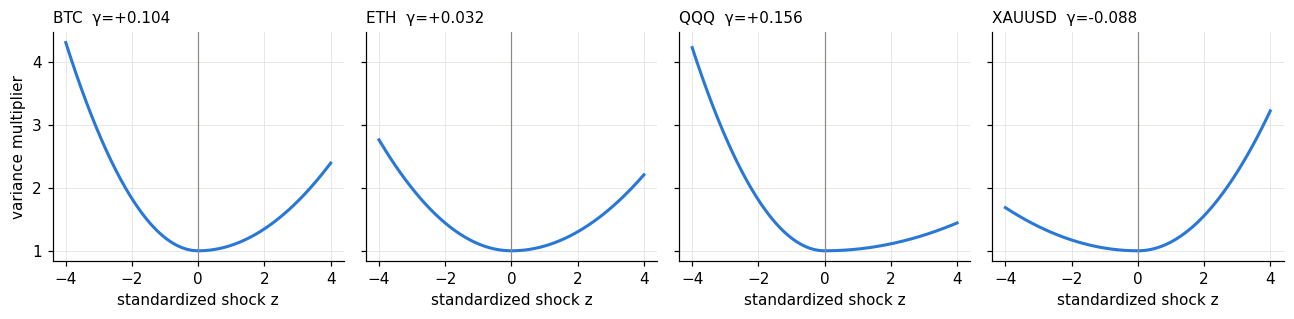

In [7]:
z = np.linspace(-4, 4, 161)
fig, axes = plt.subplots(1, len(ASSETS), figsize=(12, 3), sharey=True)
for ax, s in zip(axes, ASSETS):
    p = fits[s, 2026][0].params
    a, g, b, w = p['alpha[1]'], p['gamma[1]'], p['beta[1]'], p['omega']
    lr = w / (1 - a - g / 2 - b)
    ax.plot(z, 1 + (a + g * (z < 0)) * z**2 * lr / (w + b * lr), color=C['sigma'], lw=2)
    ax.axvline(0, color='#8a8984', lw=0.8)
    ax.set_title(f"{s}  γ={g:+.3f}", loc='left', fontsize=10)
    ax.set_xlabel('standardized shock z')
axes[0].set_ylabel('variance multiplier')
fig.tight_layout()

## In-sample conditional volatility — fold 2024 fit (2019 → 2023)

σ_t vs |r_t|, daily %, log scale. In-sample, not a forecast.

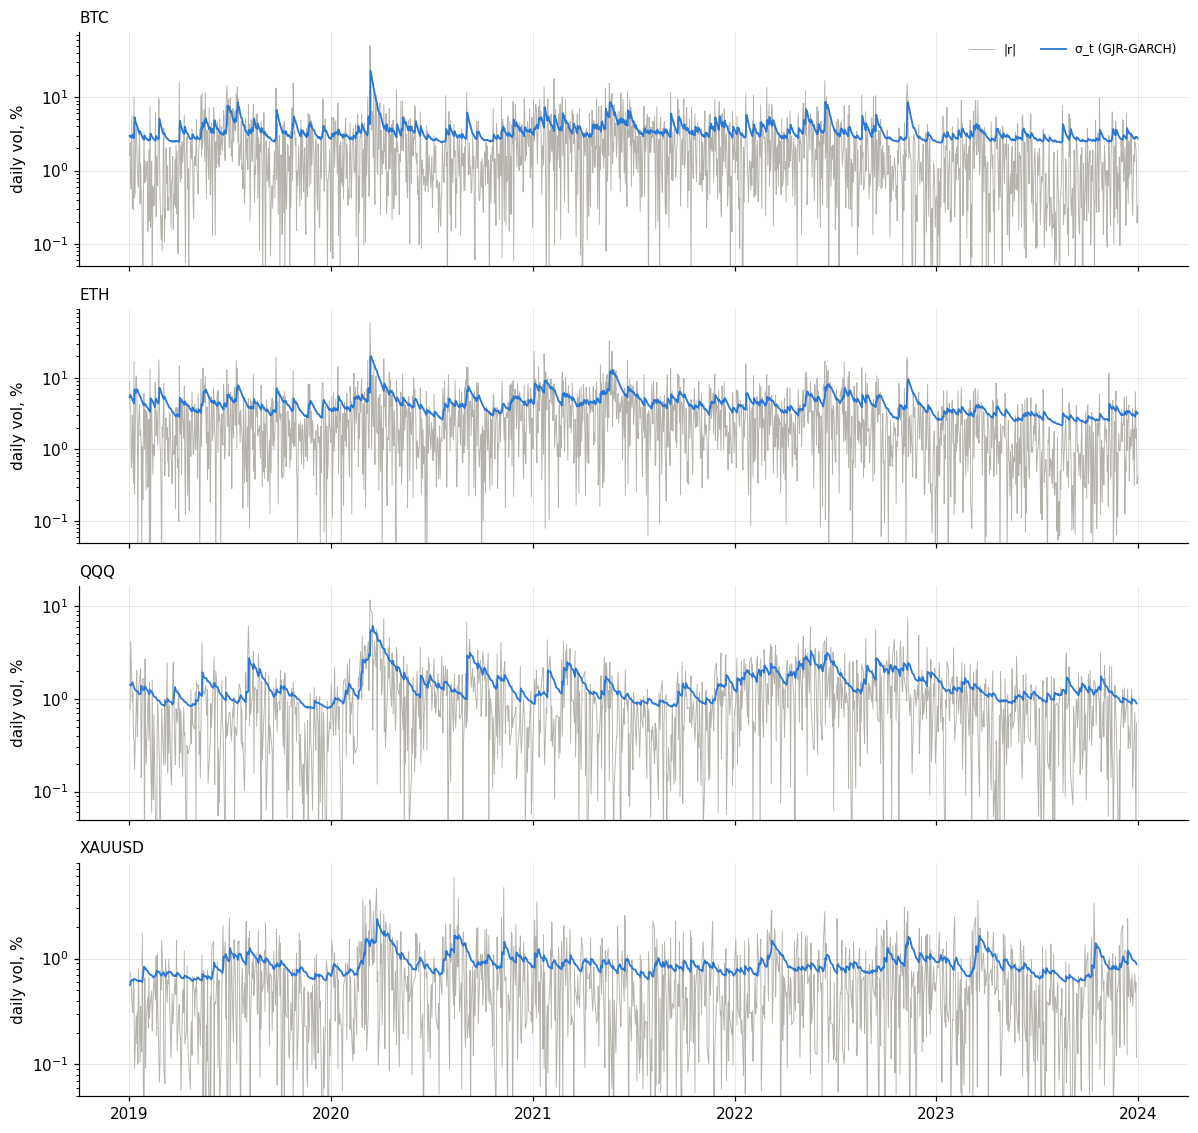

In [8]:
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    res, rf = fits[s, 2024]
    ax.plot(rf.index, rf.abs().clip(lower=0.01), color=C['realized'], lw=0.6, label='|r|')
    ax.plot(rf.index, res.conditional_volatility, color=C['sigma'], lw=1.2, label='σ_t (GJR-GARCH)')
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=2, frameon=False, fontsize=8)
fig.tight_layout()

# Walk-forward forecasts: GJR vs EGARCH vs GARCH vs HAR-YZ vs naive

Fold Y uses the parameters fitted on returns dated ≤ 31 Dec of Y−1, held fixed through Y. With fixed parameters the model runs day by day:
σ²_{t+1} = ω + (α + γ·I[r_t < 0]) r_t² + β σ²_t, using returns up to t only.

HAR-YZ, GARCH and EGARCH forecasts come from `forecasts/<SYM>-{HAR-YZ, GARCH11, EGARCH11}.csv`. Naive = `yz_var_22`. Target = `r2_next` (provisional; see README "Scoring target"). Units: %².

| Split | Target dates |
|---|---|
| Train | 2021-01-01 → 2023-12-31 |
| Test | 2024-01-01 → 2026-09-30 |

In [9]:
SPLITS = {'train': (pd.Timestamp('2021-01-01', tz='UTC'), pd.Timestamp('2024-01-01', tz='UTC')),
          'test':  (pd.Timestamp('2024-01-01', tz='UTC'), pd.Timestamp('2026-10-01', tz='UTC'))}
MODELS = ['naive', 'HAR-YZ', 'GARCH', 'EGARCH', 'GJR']

def gjr_one_step(r, p):
    """σ²_{t+1} made at the close of t, for every t, under fixed params."""
    am = arch_model(r, mean='Zero', vol='GARCH', p=1, o=1, q=1, dist='normal', rescale=False)
    sig2 = am.fix(p).conditional_volatility ** 2
    return p['omega'] + (p['alpha[1]'] + p['gamma[1]'] * (r < 0)) * r**2 + p['beta[1]'] * sig2

# cross-check against arch's own 1-step forecast
_p = fits['QQQ', 2024][0].params
_a = arch_model(rets['QQQ'], mean='Zero', vol='GARCH', p=1, o=1, q=1, rescale=False).fix(_p) \
        .forecast(horizon=1, start=0, reindex=False).variance['h.1']
assert np.allclose(gjr_one_step(rets['QQQ'], _p), _a)

def read_fc(sym, model):
    f = pd.read_csv(FC / f'{sym}-{model}.csv', index_col=0)
    f.index = pd.to_datetime(f.index, utc=True)
    f['target_date'] = pd.to_datetime(f.target_date, utc=True)
    return f

comp = {}
for s in ASSETS:
    yz = yzd[s]
    prev = {m: read_fc(s, f) for m, f in [('HAR-YZ', 'HAR-YZ'), ('GARCH', 'GARCH11'), ('EGARCH', 'EGARCH11')]}
    rows = []
    for split, (a, b) in SPLITS.items():
        o = yz.index[(yz.target_date >= a) & (yz.target_date < b)]
        years = pd.DatetimeIndex(yz.target_date.loc[o]).year
        g = pd.Series(np.nan, index=o)
        for y in np.unique(years):
            g[years == y] = gjr_one_step(rets[s], fits[s, y][0].params).reindex(o[years == y]).to_numpy()
        rows.append(pd.DataFrame({'split': split, 'fold': years, 'target_date': yz.target_date.loc[o],
                                  'naive': yz.yz_var_22.loc[o] * 1e4,
                                  **{m: f.h.reindex(o) for m, f in prev.items()},
                                  'GJR': g, 'realized': yz.r2_next.loc[o] * 1e4}, index=o))
    comp[s] = pd.concat(rows)
    assert comp[s][MODELS + ['realized']].notna().all().all(), s
    for f in prev.values():
        assert (f.target_date.reindex(comp[s].index) == comp[s].target_date).all(), s
    comp[s][['target_date', 'split', 'fold', 'GJR']].rename(columns={'GJR': 'h'}).to_csv(FC / f'{s}-GJRGARCH11.csv')
{s: c.split.value_counts().to_dict() for s, c in comp.items()}

{'BTC': {'train': 1095, 'test': 1004},
 'ETH': {'train': 1095, 'test': 1004},
 'QQQ': {'train': 753, 'test': 689},
 'XAUUSD': {'train': 773, 'test': 710}}

In [10]:
def score(f):
    ok = (f[MODELS] > 0).all(axis=1)
    g, rv = f[ok], f.realized[ok]
    out = pd.DataFrame({m: {'RMSE': np.sqrt(np.mean((g[m] - rv)**2)),
                            'QLIKE': np.mean(np.log(g[m]) + rv / g[m])} for m in MODELS}).T
    out['RMSE/naive'] = out.RMSE / out.loc['naive', 'RMSE']
    out['ΔQLIKE vs naive'] = out.QLIKE - out.loc['naive', 'QLIKE']
    out['dropped'], out['n'] = int((~ok).sum()), int(ok.sum())
    return out

scores = pd.concat({(s, sp): score(c[c.split == sp]) for s, c in comp.items() for sp in SPLITS})
scores.round(3)

RMSE  QLIKE  RMSE/naive  ΔQLIKE vs naive  dropped     n
BTC    train naive   28.457  3.428       1.000            0.000        0  1095
             HAR-YZ  26.588  3.401       0.934           -0.027        0  1095
             GARCH   27.052  3.396       0.951           -0.032        0  1095
             EGARCH  26.684  3.375       0.938           -0.053        0  1095
             GJR     27.553  3.404       0.968           -0.024        0  1095
       test  naive   14.369  2.818       1.000            0.000        0  1004
             HAR-YZ  14.595  2.876       1.016            0.058        0  1004
             GARCH   14.356  2.796       0.999           -0.021        0  1004
             EGARCH  14.278  2.812       0.994           -0.006        0  1004
             GJR     14.233  2.793       0.991           -0.025        0  1004
ETH    train naive   56.003  3.791       1.000            0.000        0  1095
             HAR-YZ  52.831  3.855       0.943            0.063        0  1095
             GARCH   52.991  3.821       0.946            0.029        0  1095
             EGARCH  52.615  3.810       0.939            0.018        0  1095
             GJR     53.116  3.848       0.948            0.057        0  1095
       test  naive   31.516  3.631       1.000            0.000        0  1004
             HAR-YZ  30.857  3.534       0.979           -0.098        0  1004
             GARCH   30.615  3.545       0.971           -0.086        0  1004
             EGARCH  30.434  3.553       0.966           -0.079        0  1004
             GJR     30.541  3.537       0.969           -0.094        0  1004
QQQ    train naive    4.066  1.634       1.000            0.000        0   753
             HAR-YZ   4.232  1.678       1.041            0.044        0   753
             GARCH    4.220  1.679       1.038            0.045        0   753
             EGARCH   4.148  1.644       1.020            0.010        0   753
             GJR      4.227  1.658       1.040            0.024        0   753
       test  naive    6.887  1.477       1.000            0.000        0   689
             HAR-YZ   6.457  1.377       0.937           -0.100        0   689
             GARCH    6.872  1.430       0.998           -0.047        0   689
             EGARCH   6.627  1.390       0.962           -0.086        0   689
             GJR      6.611  1.389       0.960           -0.088        0   689
XAUUSD train naive    1.395  0.734       1.000            0.000        0   773
             HAR-YZ   1.379  0.694       0.989           -0.041        0   773
             GARCH    1.400  0.728       1.004           -0.007        0   773
             EGARCH   1.395  0.735       1.001            0.000        0   773
             GJR      1.400  0.732       1.004           -0.002        0   773
       test  naive    4.766  1.459       1.000            0.000        0   710
             HAR-YZ   4.509  1.413       0.946           -0.047        0   710
             GARCH    4.521  1.417       0.949           -0.042        0   710
             EGARCH   4.569  1.416       0.959           -0.043        0   710
             GJR      4.526  1.404       0.950           -0.055        0   710

In [11]:
# ΔQLIKE per fold (lower = better). 'GJR − GARCH' < 0: asymmetry helped that year. 'best' = lowest QLIKE of all five
rows = {}
for s, c in comp.items():
    for y, g in c.groupby('fold'):
        q = score(g).QLIKE
        rows[s, y] = {'GJR − naive': q['GJR'] - q['naive'], 'GJR − GARCH': q['GJR'] - q['GARCH'],
                      'GJR − EGARCH': q['GJR'] - q['EGARCH'], 'GJR − HAR-YZ': q['GJR'] - q['HAR-YZ'],
                      'best': q.idxmin(), 'split': g.split.iloc[0]}
pd.DataFrame(rows).T.rename_axis(['asset', 'fold']).round(3)

GJR − naive GJR − GARCH GJR − EGARCH GJR − HAR-YZ    best  split
asset  fold                                                                 
BTC    2021     0.02866    0.032963      0.06619     0.116707  HAR-YZ  train
       2022    -0.10421   -0.011427    -0.005131     -0.01609     GJR  train
       2023    0.002068     0.00126     0.024842    -0.092901  EGARCH  train
       2024   -0.003291   -0.003959    -0.015091    -0.035834     GJR   test
       2025    0.028351    0.007504    -0.014125    -0.113076   naive   test
       2026   -0.124492   -0.017338    -0.030593    -0.106162     GJR   test
ETH    2021   -0.022723    0.025489     0.013788     0.051644  HAR-YZ  train
       2022   -0.077642   -0.007266     0.002673     0.010669  HAR-YZ  train
       2023    0.271526    0.064895     0.099583    -0.080716   naive  train
       2024    -0.00414   -0.002762     0.013825    -0.021388  EGARCH   test
       2025   -0.124059   -0.003187    -0.008837     0.040808  HAR-YZ   test
       2026   -0.175832   -0.021275    -0.064902    -0.014519     GJR   test
QQQ    2021   -0.000471   -0.025375     0.002524     0.023188  HAR-YZ  train
       2022     0.05346   -0.012302     0.039668    -0.053588   naive  train
       2023    0.019933   -0.025217     0.000502    -0.028979   naive  train
       2024   -0.056752   -0.013071     0.004304     0.001436  EGARCH   test
       2025   -0.145063   -0.059539     0.001881     0.008101  HAR-YZ   test
       2026   -0.052247   -0.051559    -0.012805      0.03172  HAR-YZ   test
XAUUSD 2021    0.039442    0.010955    -0.014378     0.073696  HAR-YZ  train
       2022     0.04079   -0.001137     0.006065     0.063631  HAR-YZ  train
       2023   -0.087884    0.003158    -0.000165    -0.022998   GARCH  train
       2024   -0.074851     -0.0164     0.002651    -0.022928  EGARCH   test
       2025   -0.094713   -0.032257     -0.00902    -0.030547     GJR   test
       2026    0.024131    0.016067    -0.036874     0.040639  HAR-YZ   test

## Test forecasts vs realized: the GARCH family (daily volatility, %, log scale)

√(forecast variance) vs |next-day return|. HAR-YZ and naive are left out to keep the plot readable (they are in the tables).

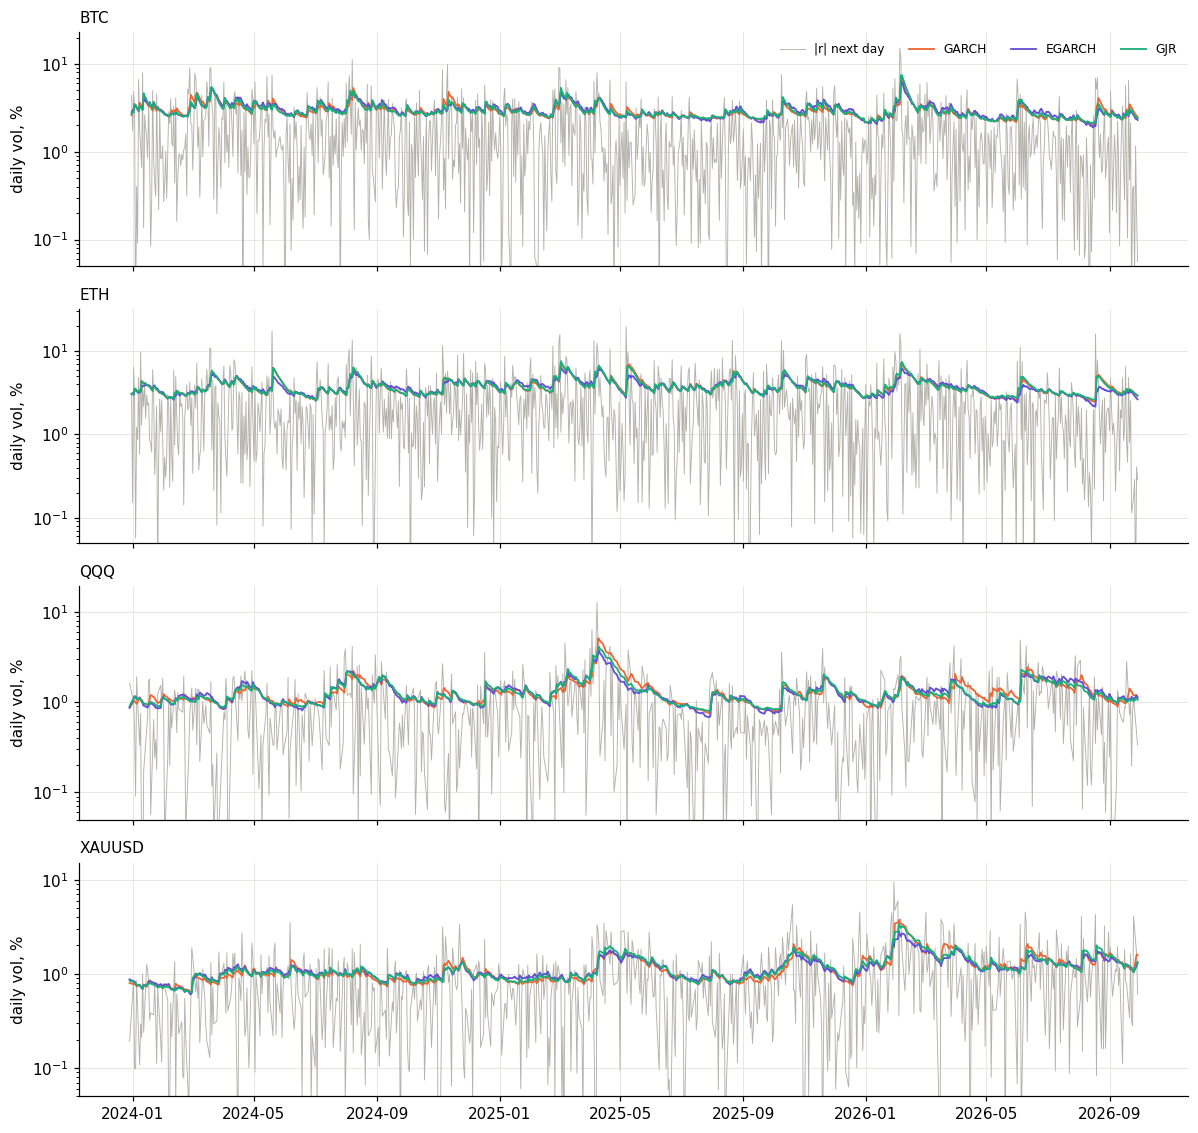

In [12]:
CC = {'realized': '#b4b2ab', 'GARCH': '#eb6834', 'EGARCH': '#6250d6', 'GJR': '#1baf7a'}
fig, axes = plt.subplots(len(ASSETS), 1, figsize=(11, 2.6 * len(ASSETS)), sharex=True)
for ax, s in zip(axes, ASSETS):
    f = comp[s][comp[s].split == 'test']
    ax.plot(f.index, np.sqrt(f.realized), color=CC['realized'], lw=0.6, label='|r| next day')
    for m in ['GARCH', 'EGARCH', 'GJR']:
        ax.plot(f.index, np.sqrt(f[m]), color=CC[m], lw=1.2, label=m)
    ax.set_yscale('log'); ax.set_ylim(bottom=0.05)
    ax.set_title(s, loc='left', fontsize=10); ax.set_ylabel('daily vol, %')
axes[0].legend(loc='upper right', ncol=4, frameon=False, fontsize=8)
fig.tight_layout()

## Findings (run 2026-11-01; target r², provisional)

**Fit:** all 24 fits converge cleanly (flag 0, no warnings, finite SEs, constraints met, persistence ≤ 0.990). All 18 restarts per fit reach the same peak (gain 0.0, parameter ranges ≤ 1e-4).

**Asymmetry agrees with EGARCH** (note the sign convention: GJR γ > 0 = leverage; EGARCH γ < 0 = leverage):

| Asset | GJR γ | Significant? | Up-day weight α → down-day α+γ (fold 2026) | Meaning |
|---|---|---|---|---|
| QQQ | +0.13 to +0.18 | Yes from fold 2023 (p ≤ 0.03) | 0.025 → 0.181 | Down moves dominate: almost all of the shock response comes on down days |
| XAUUSD | **−0.07 to −0.14** | Yes, all 6 folds (p < 0.05) | 0.127 → 0.039 | **Up** moves raise vol ~3× more |
| BTC | +0.10 to +0.33 | No (p 0.21–0.36) | 0.076 → 0.180 | Tilt, not established |
| ETH | +0.01 to +0.20 | No (p 0.30–0.90) | 0.069 → 0.101 | Symmetric |

**All five forecasts on test (2024 → 2026-09), QLIKE vs naive (lower = better):**

| Asset | HAR-YZ | GARCH | EGARCH | GJR | Best |
|---|---:|---:|---:|---:|---|
| BTC | +0.058 | −0.021 | −0.006 | **−0.025** | GJR ≈ GARCH |
| ETH | **−0.098** | −0.086 | −0.079 | −0.094 | HAR-YZ ≈ GJR |
| QQQ | **−0.100** | −0.047 | −0.086 | −0.088 | HAR-YZ, then GJR ≈ EGARCH |
| XAUUSD | −0.047 | −0.042 | −0.043 | **−0.055** | GJR |

- **GJR improves on GARCH more often than EGARCH does:** lower QLIKE in 16 of 24 asset-years, and in 10 of 12 test asset-years. The gain is largest for QQQ (all 6 years, test −0.088 vs −0.047), where the leverage effect is significant.
- **GJR vs EGARCH:** a near-tie for QQQ. GJR is ahead on test for the other three (BTC −0.025 vs −0.006, ETH −0.094 vs −0.079, gold −0.055 vs −0.043).
- **GJR is the best or joint-best GARCH-family model on test for every asset.** HAR-YZ still leads QQQ and, narrowly, ETH. On train, EGARCH was best of the family for BTC, ETH and QQQ, so the family ranking isn't stable between train and test either.
- **Gaps are small** (mostly ≤ 0.02 between the best two). Diebold–Mariano still pending before picking a representation per asset.
- Forecasts saved to `forecasts/<SYM>-GJRGARCH11.csv`.